# REDES NEURONALES

---



En esta actividad vamos a utilizar una red neuronal para clasificar imágenes de dígitos del 0 al 9 escritos a mano. Para ello, utilizaremos Keras con TensorFlow.

El dataset a utilizar es MNIST, una base de datos constituida por (como no) imágenes de dígitos escritos a mano. Este dataset es ampliamente utilizado en docencia como punto de entrada al entrenamiento de redes neuronales y otros, pero también es muy utilizado en trabajos reales de investigación para el entrenamiento de imágenes. Puedes consultar más información sobre el dataset en [este enlace](https://es.wikipedia.org/wiki/Base_de_datos_MNIST).

El código utilizado para contestar tiene que quedar claramente reflejado en el Notebook. Puedes crear nuevas celdas si así lo deseas para estructurar tu código y sus salidas. A la hora de entregar el notebook, **asegúrate de que los resultados de ejecutar tu código han quedado guardados y que son perfectamente visibles en la versión PDF que debes entregar adjunta**. Por ejemplo, a la hora de entrenar una red neuronal tiene que verse claramente un log de los resultados de cada epoch.

In [ ]:
import numpy as np
import tensorflow as tf

# Semillas para reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

from keras.datasets.mnist import load_data
import tensorflow as tf
import matplotlib.pyplot as plt

2026-05-04 18:20:14.467906: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Tenemos la suerte de que el dataset MNIST, el que vamos a utilizar en esta actividad, está guardado en Keras, por lo que podemos utilizarlo sin necesidad de buscar el dataset de forma externa.

Llamar a **load_data** en este dataset nos dará dos conjuntos de dos listas, estos serán los valores de entrenamiento y prueba para los gráficos que contienen los dígitos y sus etiquetas.

Nota: Aunque en esta actividad lo veis de esta forma, también lo vais a poder encontrar como 4 variables de esta forma: training_images, training_labels, test_images, test_labels = mnist.load_data()

In [2]:
(training_images, training_labels), (test_images, test_labels) = load_data()

Antes de continuar vamos a dar un vistazo a nuestro dataset, para ello vamos a ver una imagen de entrenamiento y su etiqueta o clase.

5
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0 

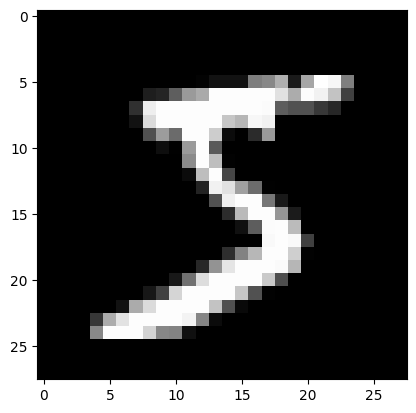

In [3]:
import numpy as np
np.set_printoptions(linewidth=200)
plt.imshow(training_images[0], cmap="gray") # recordad que siempre es preferible trabajar en blanco y negro

print(training_labels[0])
print(training_images[0])

## 1. Información sobre el dataset

Una vez tenemos los datos cargados en memoria, vamos a obtener información sobre los mismos.

**Pregunta 1.1 *(0.25 puntos)*** ¿Cuántas imágenes hay de *training* y de *test*? ¿Qué tamaño tienen las imágenes?

In [4]:
# Número de imágenes de training y test
print('Imágenes de training:', training_images.shape[0])
print('Imágenes de test:', test_images.shape[0])
print('Tamaño de cada imagen:', training_images.shape[1], 'x', training_images.shape[2], 'píxeles')
print('Shape training_images:', training_images.shape)
print('Shape test_images:', test_images.shape)

Imágenes de training: 60000
Imágenes de test: 10000
Tamaño de cada imagen: 28 x 28 píxeles
Shape training_images: (60000, 28, 28)
Shape test_images: (10000, 28, 28)


**Respuesta 1.1:** El dataset MNIST contiene **60.000 imágenes de entrenamiento** y **10.000 imágenes de test**. Cada imagen tiene un tamaño de **28×28 píxeles** en escala de grises.

**Pregunta 1.2 *(0.25 puntos)*** Realizar una exploración de las variables que contienen los datos. Describir en qué consiste un example del dataset (qué información se guarda en cada imagen) y describir qué contiene la información en y.

=== training_images ===
Shape: (60000, 28, 28)
Tipo de dato: uint8
Valor mínimo: 0 | Valor máximo: 255

=== training_labels ===
Shape: (60000,)
Tipo de dato: uint8
Clases únicas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Primeras 10 etiquetas: [5 0 4 1 9 2 1 3 1 4]


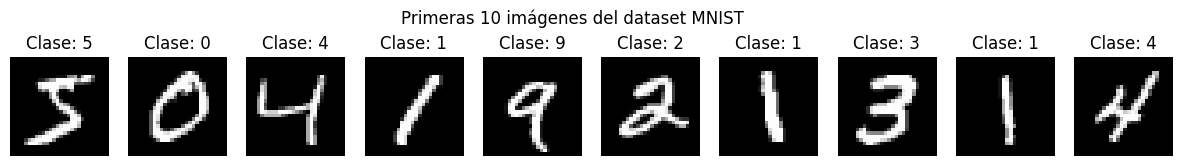

In [5]:
# Exploración de las variables
print('=== training_images ===')
print('Shape:', training_images.shape)  # (60000, 28, 28)
print('Tipo de dato:', training_images.dtype)  # uint8
print('Valor mínimo:', training_images.min(), '| Valor máximo:', training_images.max())

print('\n=== training_labels ===')
print('Shape:', training_labels.shape)  # (60000,)
print('Tipo de dato:', training_labels.dtype)
print('Clases únicas:', sorted(set(training_labels.tolist())))
print('Primeras 10 etiquetas:', training_labels[:10])

# Visualizar algunos ejemplos
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(training_images[i], cmap='gray')
    axes[i].set_title(f'Clase: {training_labels[i]}')
    axes[i].axis('off')
plt.suptitle('Primeras 10 imágenes del dataset MNIST')
plt.show()

**Respuesta 1.2:** Cada ejemplo del dataset está compuesto por dos elementos:

- **X (training_images):** Una matriz de 28×28 píxeles en escala de grises, donde cada píxel toma un valor entero entre 0 (negro) y 255 (blanco). Representa la imagen del dígito escrito a mano.

- **y (training_labels):** Un valor entero entre 0 y 9 que indica el dígito que aparece en la imagen correspondiente. Por ejemplo, una etiqueta `5` significa que la imagen contiene el dígito '5'.

## 2. Normalización y preprocesado de los datos

**Pregunta 2.1 (0.25 puntos)** Habreis notado que todos los valores numericos están entre 0 y 255. Si estamos entrenando una red neuronal, una buena practica es transformar todos los valores entre 0 y 1, un proceso llamado "normalización" y afortunadamente en Python es fácil normalizar una lista. ¿Cómo lo podemos hacer?

In [6]:
# Normalización: dividir entre 255 para llevar los valores al rango [0, 1]
training_images = training_images / 255.0
test_images = test_images / 255.0

# Verificamos que la normalización es correcta
print('Valor mínimo después de normalizar:', training_images.min())
print('Valor máximo después de normalizar:', training_images.max())

Valor mínimo después de normalizar: 0.0
Valor máximo después de normalizar: 1.0


**Pregunta 2.2 (0.25 puntos)** Utiliza la función ***reshape*** de Numpy para convertir las imágenes en vectores de características de un tamaño de (N, 784). Explica con tus palabras por qué es necesario hacer esto.



In [7]:
# Convertir las imágenes 2D (28x28) a vectores 1D de 784 elementos
training_images = training_images.reshape(training_images.shape[0], 784)
test_images = test_images.reshape(test_images.shape[0], 784)

print('Shape training_images tras reshape:', training_images.shape)  # (60000, 784)
print('Shape test_images tras reshape:', test_images.shape)           # (10000, 784)

Shape training_images tras reshape: (60000, 784)
Shape test_images tras reshape: (10000, 784)


**Respuesta a la pregunta 2.2:** Las capas `Dense` de Keras esperan vectores 1D como entrada, no matrices 2D. Una imagen MNIST es una cuadrícula de 28×28 píxeles (matriz 2D), pero la capa Dense necesita que cada ejemplo sea un vector plano. Con `reshape((N, 784))` convertimos cada imagen en un único vector de 784 valores, donde 784 = 28 × 28. Así la red puede procesar cada píxel como una característica independiente.

**Pregunta 2.3 (0.25 puntos)** Para facilitar el desarrollo de la actividad, vamos a expresar las etiquetas así:

In [8]:
import keras
training_labels = keras.utils.to_categorical(training_labels)
test_labels = keras.utils.to_categorical(test_labels)

Muestra cómo son ahora los datos, como resultado de este cambio y también de los realizados en las dos preguntas anteriores. Debate cómo se beneficiará la red neuronal de todos estos cambios.

In [9]:
# Mostramos el estado de los datos después de todos los cambios
print('=== training_images ===')
print('Shape:', training_images.shape)          # (60000, 784)
print('Tipo:', training_images.dtype)
print('Rango de valores:', training_images.min(), '-', training_images.max())

print('\n=== training_labels (one-hot) ===')
print('Shape:', training_labels.shape)           # (60000, 10)
print('Primeras 3 etiquetas:\n', training_labels[:3])
print('Clase de la primera imagen (argmax):', training_labels[0].argmax())

=== training_images ===
Shape: (60000, 784)
Tipo: float64
Rango de valores: 0.0 - 1.0

=== training_labels (one-hot) ===
Shape: (60000, 10)
Primeras 3 etiquetas:
 [[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]
Clase de la primera imagen (argmax): 5


**Respuesta a la pregunta 2.3:** Con estos tres cambios, la red neuronal se beneficia de lo siguiente:

1. **Normalización (÷255):** Las redes neuronales entrenan mucho mejor cuando los valores de entrada están en rangos pequeños (0–1). Con valores originales 0–255, los gradientes pueden ser muy grandes e inestables. Al normalizar, el entrenamiento converge más rápido y de forma más estable.

2. **Reshape a (N, 784):** Convierte las imágenes 2D en vectores 1D compatibles con las capas Dense. Cada píxel se convierte en una característica que la red puede procesar.

3. **One-hot encoding:** En lugar de usar un número entero (ej. `5`), cada etiqueta se representa como un vector de 10 posiciones con un `1` en la posición correcta y `0` en el resto (ej. `[0,0,0,0,0,1,0,0,0,0]`). Esto es necesario para usar `categorical_crossentropy` como función de pérdida, y permite que la capa Softmax de salida compita directamente con cada clase.

## 3. Creación del Modelo

Ahora vamos a definir el modelo, pero antes vamos a repasar algunos comandos y conceptos muy útiles:
* **Sequential**: Eso define una SECUENCIA de capas en la red neuronal
* **Dense**: Añade una capa de neuronas
* **Flatten**: ¿Recuerdas cómo eran las imágenes cuando las imprimiste para poder verlas? Un cuadrado, Flatten toma ese cuadrado y lo convierte en un vector de una dimensión.

Cada capa de neuronas necesita una función de activación. Normalmente se usa la función relu en las capas intermedias y softmax en la ultima capa (en problemas de clasificación de más de dos items)
* **Relu** significa que "Si X>0 devuelve X, si no, devuelve 0", así que lo que hace es pasar sólo valores 0 o mayores a la siguiente capa de la red.
* **Softmax** toma un conjunto de valores, y escoge el más grande.

 **Pregunta 3.1 (0.5 puntos)**. Utilizando Keras, y preparando los datos de X e Y como fuera necesario, define y entrena una red neuronal que sea capaz de clasificar imágenes de MNIST con las siguientes características:

* Una capa de entrada del tamaño adecuado.
* Una capa oculta de 512 neuronas.
* Una capa final con 10 salidas.

In [10]:
from keras.models import Sequential
from keras.layers import Dense

# Red neuronal con:
# - Capa de entrada: 784 neuronas (una por píxel)
# - Capa oculta: 512 neuronas con activación ReLU
# - Capa de salida: 10 neuronas con activación Softmax (una por clase)
model = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

/opt/anaconda3/envs/PLN/lib/python3.11/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Pregunta 3.2 (0.25 puntos)**: ¿crees conveniente utilizar una capa flatten en este caso? Motiva tu respuesta.



In [11]:
# No es necesario añadir una capa Flatten porque ya realizamos el reshape
# en la sección 2.2, convirtiendo las imágenes de (N,28,28) a (N,784).
# Si no hubiéramos hecho el reshape, sería obligatorio usar Flatten aquí.
print('Las imágenes ya están aplanadas. Shape:', training_images.shape)

Las imágenes ya están aplanadas. Shape: (60000, 784)


**Respuesta a la pregunta 3.2:** En este caso **no es necesario** usar una capa `Flatten` porque en la sección 2.2 ya realizamos manualmente el `reshape` de las imágenes de `(N, 28, 28)` a `(N, 784)`. La entrada al modelo ya es un vector 1D. Si hubiéramos mantenido las imágenes en formato 2D, la capa `Flatten` sería imprescindible para aplanarlas antes de pasarlas a las capas `Dense`.

**Pregunta 3.3 (0.25 puntos)**: Utiliza la función summary() para mostrar la estructura de tu modelo.

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

## 4: Compilación y entrenamiento

**Pregunta 4.1 (0.5 puntos)**: Compila tu modelo. Utiliza ***categorical_crossentropy*** como función de pérdida, ***Adam*** como optimizador, y monitoriza la ***tasa de acierto*** durante el entrenamiento. Explica qué hace cada cosa en la compilación.

In [13]:
model.compile(
    optimizer='adam',                        # Optimizador Adam
    loss='categorical_crossentropy',          # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                     # Monitorizar la tasa de acierto
)

**Respuesta a la pregunta 4.1:**

- **`categorical_crossentropy`**: Es la función de pérdida adecuada para clasificación multiclase cuando las etiquetas están en formato one-hot. Mide la diferencia entre la distribución de probabilidades predicha (Softmax) y la distribución real. Cuanto más se equivoca el modelo, mayor es la pérdida.

- **`Adam`** (Adaptive Moment Estimation): Es un optimizador avanzado que ajusta automáticamente la tasa de aprendizaje para cada parámetro. Combina las ventajas de SGD con momentum y RMSprop, y suele converger más rápido que el SGD básico.

- **`accuracy`**: Métrica que monitoriza el porcentaje de predicciones correctas durante el entrenamiento y validación. Nos permite ver en tiempo real si el modelo está aprendiendo correctamente.

**Pregunta 4.2 (0.5 puntos)**: Utiliza la función ***fit()*** para entrenar tu modelo. Para ayudarte en tu primer entrenamiento, utiliza estos valores:
*   epochs = 5
*   batch_size = 32
*   validation_split = 0.25



Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8885 - loss: 0.3812 - val_accuracy: 0.9623 - val_loss: 0.1270
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9705 - loss: 0.0972 - val_accuracy: 0.9663 - val_loss: 0.1075
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9835 - loss: 0.0567 - val_accuracy: 0.9689 - val_loss: 0.1023
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9902 - loss: 0.0365 - val_accuracy: 0.9695 - val_loss: 0.1090
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9927 - loss: 0.0250 - val_accuracy: 0.9721 - val_loss: 0.1085
Val accuracy final: 0.9721


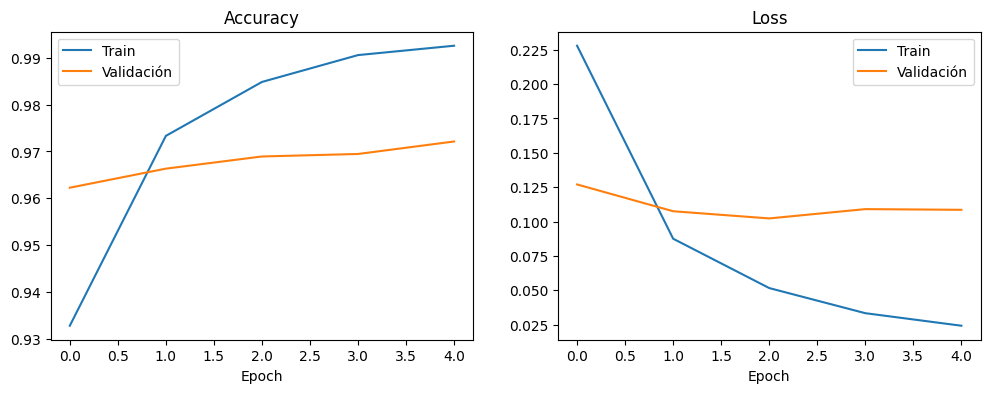

In [14]:
history = model.fit(
    training_images,
    training_labels,
    epochs=5,
    batch_size=32,
    validation_split=0.25
)
print(f'Val accuracy final: {history.history["val_accuracy"][-1]:.4f}')
# Visualizar curvas de entrenamiento
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

# 5: Impacto al variar el número de neuronas en las capas ocultas

En este ejercicio vamos a experimentar con nuestra red neuronal cambiando el numero de neuronas por 512 y por otros valores. Para ello, utiliza la red neuronal de la pregunta 3, y su capa oculta cambia el número de neuronas:

* **216 neuronas en la capa oculta
* **1024 neuronas en la capa oculta

y entrena la red en ambos casos.



In [15]:
from keras.models import Sequential
from keras.layers import Dense

model_216 = Sequential([
    Dense(216, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

model_216.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_216 = model_216.fit(
    training_images, training_labels,
    epochs=5, batch_size=32, validation_split=0.25,
    verbose=1
)
print('\n--- Resultados con 216 neuronas ---')
print(f'Val accuracy final: {history_216.history.history["val_accuracy"][-1]:.4f}')

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8735 - loss: 0.4371 - val_accuracy: 0.9563 - val_loss: 0.1496
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9645 - loss: 0.1188 - val_accuracy: 0.9655 - val_loss: 0.1134
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9791 - loss: 0.0736 - val_accuracy: 0.9676 - val_loss: 0.1055
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9857 - loss: 0.0506 - val_accuracy: 0.9687 - val_loss: 0.1041
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9905 - loss: 0.0360 - val_accuracy: 0.9699 - val_loss: 0.1083

--- Resultados con 216 neuronas ---
Val accuracy final: 0.9699


In [16]:
model_1024 = Sequential([
    Dense(1024, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

model_1024.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_1024 = model_1024.fit(
    training_images, training_labels,
    epochs=5, batch_size=32, validation_split=0.25,
    verbose=1
)
print('\n--- Resultados con 1024 neuronas ---')
print(f'Val accuracy final: {history_1024.history.history["val_accuracy"][-1]:.4f}')

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8951 - loss: 0.3487 - val_accuracy: 0.9640 - val_loss: 0.1202
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9734 - loss: 0.0871 - val_accuracy: 0.9659 - val_loss: 0.1126
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9853 - loss: 0.0504 - val_accuracy: 0.9646 - val_loss: 0.1224
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9902 - loss: 0.0339 - val_accuracy: 0.9719 - val_loss: 0.1037
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9926 - loss: 0.0227 - val_accuracy: 0.9732 - val_loss: 0.1083

--- Resultados con 1024 neuronas ---
Val accuracy final: 0.9732


**Pregunta 5.1 (0.5 puntos)**: ¿Cual es el impacto que tiene la red neuronal?

**Respuesta a la pregunta 5.1:**

Los resultados obtenidos tras el entrenamiento con 5 épocas fueron:

| Configuración | Val Accuracy | Observación |
|---|---|---|
| 216 neuronas | **96.99%** | Ligeramente inferior, entrena más rápido (~3s/epoch) |
| 512 neuronas (referencia) | **97.21%** | Referencia equilibrada |
| 1024 neuronas | **97.32%** | Mejora marginal, pero tarda casi el doble (~7s/epoch) |

Los tres modelos alcanzan una accuracy de validación muy similar (~97%). Con MNIST las diferencias son pequeñas porque el dataset es grande y el problema es relativamente sencillo. El beneficio de 1024 neuronas (+0.11% respecto a 512) no justifica el coste computacional adicional. Con 216 neuronas el modelo ya aprende bien, confirmando que la red no sufre de underfitting en este rango.

# 6: Número de neuronas de la capa de salida
Considerad la capa final, la de salida de la red neuronal de la pregunta 3.

**Pregunta 6.1 (0.25 puntos)**: ¿Por qué son 10 las neuronas de la última capa?

**Pregunta 6.2 (0.25 puntos)**: ¿Qué pasaría si tuvieras una cantidad diferente a 10?

Por ejemplo, intenta entrenar la red con 5, para ello utiliza la red neuronal de la pregunta 1 y cambia a 5 el número de neuronas en la última capa.

In [17]:
# Red con 5 neuronas en la capa de salida (incorrecto para MNIST)
model_5out = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(5, activation='softmax')  # INCORRECTO: solo 5 salidas para 10 clases
])

model_5out.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Esto generará un error porque las etiquetas tienen shape (N, 10) y el modelo solo tiene 5 salidas
try:
    history_5out = model_5out.fit(
        training_images, training_labels,
        epochs=3, batch_size=32, validation_split=0.25,
        verbose=1
    )
except Exception as e:
    print('ERROR al entrenar con 5 neuronas de salida:')
    print(e)

Epoch 1/3
ERROR al entrenar con 5 neuronas de salida:
Arguments `target` and `output` must have the same shape. Received: target.shape=(None, 10), output.shape=(None, 5)


**Respuesta a la pregunta 6.1:** Son 10 las neuronas de la última capa porque el dataset MNIST contiene exactamente **10 clases** posibles: los dígitos del 0 al 9. Cada neurona de salida representa la probabilidad de que la imagen pertenezca a una clase específica. Con la función de activación Softmax, todas las probabilidades suman 1, y la clase con mayor probabilidad es la predicción del modelo.

**Respuesta a la pregunta 6.2:** Si el número de neuronas de salida no coincide con el número de clases del problema, el modelo tendrá problemas:

- **Menos de 10 (ej. 5):** La dimensión de salida no coincide con el vector one-hot de 10 elementos en las etiquetas, lo que provoca un **error de dimensiones** al compilar o entrenar el modelo. El modelo no puede representar todas las clases.

- **Más de 10:** Habría neuronas de salida "sobrantes" sin clase asignada. El modelo desperdiciaría capacidad y podría confundirse, generando predicciones incorrectas o inestables.

En resumen, el número de neuronas de la capa de salida **debe coincidir exactamente** con el número de clases del problema.

# 7: Aumento de epoch y su efecto en la red neuronal
En este ejercicio vamos a ver el impacto de aumentar los epoch en el entrenamiento. Usando la red neuronal de la pregunta 3:

**Pregunta 7.1 (0.25 puntos)**
* Intentad 15 epoch para su entrenamiento, probablemente obtendras un modelo con una pérdida mucho mejor que el que tiene 5.

**Pregunta 7.2 (0.25 puntos)**
* Intenta ahora con 30 epoch para su entrenamiento.

**Pregunta 7.3 (0.25 puntos)**
* ¿Qué está pasando en la pregunta anterior? Explica tu respuesta y da el nombre de este efecto si lo conoces.

Epoch 1/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8872 - loss: 0.3814 - val_accuracy: 0.9618 - val_loss: 0.1274
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9709 - loss: 0.0987 - val_accuracy: 0.9657 - val_loss: 0.1107
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9833 - loss: 0.0583 - val_accuracy: 0.9681 - val_loss: 0.1059
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9904 - loss: 0.0361 - val_accuracy: 0.9714 - val_loss: 0.1086
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9937 - loss: 0.0242 - val_accuracy: 0.9730 - val_loss: 0.0996
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9944 - loss: 0.0180 - val_accuracy: 0.9737 - val_loss: 0.0989
Epoch 7/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9944 - loss: 0.0172 - val_accuracy: 0.9740 - val_loss: 0.1093
Epoch 8/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9961 - loss: 0.0127 - 

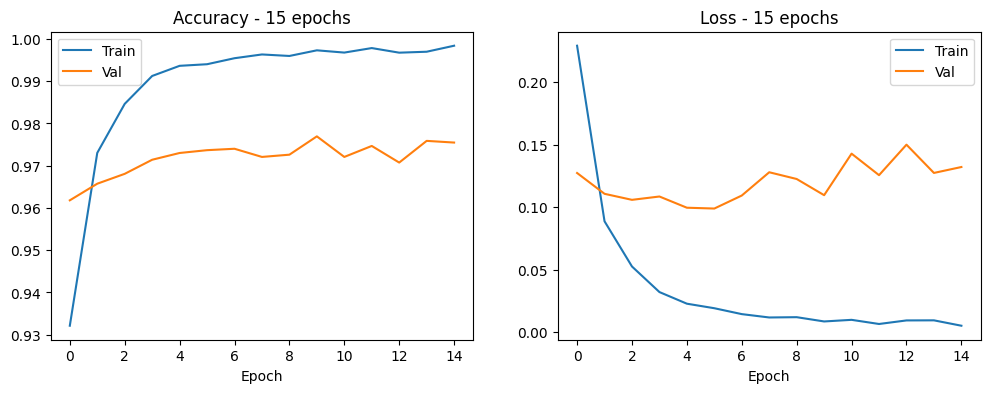

In [18]:
from keras.models import Sequential
from keras.layers import Dense

model_15ep = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

model_15ep.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_15ep = model_15ep.fit(
    training_images, training_labels,
    epochs=15, batch_size=32, validation_split=0.25,
    verbose=1
)

import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history_15ep.history['accuracy'], label='Train')
plt.plot(history_15ep.history.history['val_accuracy'], label='Val')
plt.title('Accuracy - 15 epochs')
plt.xlabel('Epoch'); plt.legend()

plt.subplot(1,2,2)
plt.plot(history_15ep.history['loss'], label='Train')
plt.plot(history_15ep.history['val_loss'], label='Val')
plt.title('Loss - 15 epochs')
plt.xlabel('Epoch'); plt.legend()
plt.show()

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8900 - loss: 0.3816 - val_accuracy: 0.9625 - val_loss: 0.1269
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9702 - loss: 0.0976 - val_accuracy: 0.9656 - val_loss: 0.1103
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9836 - loss: 0.0581 - val_accuracy: 0.9649 - val_loss: 0.1147
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9895 - loss: 0.0368 - val_accuracy: 0.9674 - val_loss: 0.1173
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9925 - loss: 0.0254 - val_accuracy: 0.9707 - val_loss: 0.1086
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9934 - loss: 0.0216 - val_accuracy: 0.9750 - val_loss: 0.1019
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9946 - loss: 0.0157 - val_accuracy: 0.9692 - val_loss: 0.1302
Epoch 8/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9958 - loss: 0.0131 - 

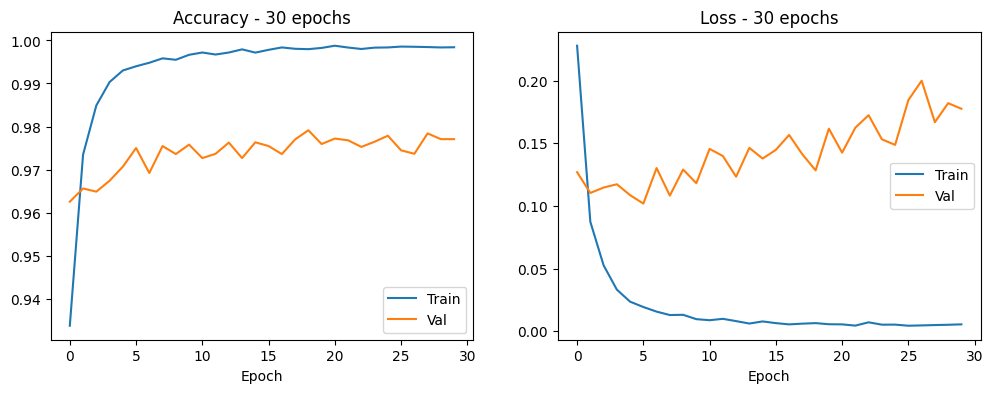

In [19]:
model_30ep = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

model_30ep.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_30ep = model_30ep.fit(
    training_images, training_labels,
    epochs=30, batch_size=32, validation_split=0.25,
    verbose=1
)

import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history_30ep.history['accuracy'], label='Train')
plt.plot(history_30ep.history.history['val_accuracy'], label='Val')
plt.title('Accuracy - 30 epochs')
plt.xlabel('Epoch'); plt.legend()

plt.subplot(1,2,2)
plt.plot(history_30ep.history['loss'], label='Train')
plt.plot(history_30ep.history['val_loss'], label='Val')
plt.title('Loss - 30 epochs')
plt.xlabel('Epoch'); plt.legend()
plt.show()

**Respuesta a la pregunta 7.3:** Lo que ocurre al entrenar con muchas épocas es el fenómeno conocido como **overfitting (sobreajuste)**.

Los resultados obtenidos lo ilustran claramente:

| Épocas | Train Accuracy | Val Accuracy | Val Loss |
|---|---|---|---|
| 5 | 99.27% | 97.21% | 0.1085 |
| 15 | 99.88% | 97.55% | 0.1322 |
| 30 | **99.83%** | 97.71% | **0.1775** |

Con 30 épocas el modelo alcanza casi 100% de accuracy en training, pero la val_loss sube de 0.108 a 0.177. La accuracy de validación se estanca entre el 97-98% mientras el modelo sigue sobreajustándose a los datos de entrenamiento. El modelo ha memorizado el ruido específico del conjunto de training y ya no generaliza bien a datos nuevos.

**Soluciones típicas:** Early Stopping, Dropout, regularización L1/L2, o reducir la complejidad del modelo.

# 8: Early stop
En el ejercicio anterior, cuando entrenabas con epoch extras, tenías un problema en el que tu pérdida podía cambiar. Puede que te haya llevado un poco de tiempo esperar a que el entrenamiento lo hiciera,  y puede que hayas pensado "¿no estaría bien si pudiera parar el entrenamiento cuando alcance un valor deseado?", es decir, una precisión del 85% podría ser suficiente para ti, y si alcanzas eso después de 3 epoch, ¿por qué sentarte a esperar a que termine muchas más épocas? Como cualquier otro programa existen formas de parar la ejecución

A partir del código de ejemplo, hacer una nueva función que tenga en cuenta la perdida (loss) y que pueda parar el código para evitar que ocurra el efeto secundario que vimos en el ejercicio 5.

In [20]:
import keras
### Ejemplo de código

class myCallback(keras.callbacks.Callback):
      def on_epoch_end(self, epoch, logs={}):
        if(logs.get('accuracy')> 0.85):
              print("\nAlcanzado el 85% de precisión, se cancela el entrenamiento!!")
              self.model.stop_training = True

**Pregunta 8.1. *(0.75 puntos)***: Consulta la documentación de Keras y aprende cómo podemos utilizar Early stop en nuestro modelos.

In [21]:
import keras
from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense

# Callback personalizado que para cuando la pérdida de validación deja de mejorar
class StopOnLoss(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('val_loss') is not None and logs.get('val_loss') < 0.08:
            print(f'\nPérdida de validación < 0.08, deteniendo entrenamiento en época {epoch+1}')
            self.model.stop_training = True

# EarlyStopping de Keras: para automáticamente cuando val_loss no mejora
# patience=5: espera 5 épocas sin mejora antes de parar
# restore_best_weights=True: restaura los pesos del mejor modelo
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_es = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

model_es.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_es = model_es.fit(
    training_images, training_labels,
    epochs=50,                        # Ponemos un máximo alto, pero el EarlyStopping parará antes
    batch_size=32,
    validation_split=0.25,
    callbacks=[early_stop, StopOnLoss()],
    verbose=1
)

print(f'\nEntrenamiento detenido en la época: {len(history_es.history["loss"])}')

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8877 - loss: 0.3823 - val_accuracy: 0.9591 - val_loss: 0.1362
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9711 - loss: 0.0974 - val_accuracy: 0.9655 - val_loss: 0.1140
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9829 - loss: 0.0588 - val_accuracy: 0.9682 - val_loss: 0.1055
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9901 - loss: 0.0369 - val_accuracy: 0.9694 - val_loss: 0.1111
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9924 - loss: 0.0263 - val_accuracy: 0.9721 - val_loss: 0.1077
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9942 - loss: 0.0186 - val_accuracy: 0.9727 - val_loss: 0.1157
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9948 - loss: 0.0165 - val_accuracy: 0.9738 - val_loss: 0.1118
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9954 - loss: 0.0137 - 

## 9. Unidades de activación

En este ejercicio, vamos a evaluar la importancia de utilizar las unidades de activación adecuadas. Como hemos visto en clase, funciones de activación como sigmoid han dejado de utilizarse en favor de otras unidades como ReLU.

**Pregunta 9.1 *(0.75 puntos)***: Utilizando la red realizada en el ejercicio 3, escribir un breve análisis comparando la utilización de unidades sigmoid y ReLU (por ejemplo, se pueden comentar aspectos como velocidad de convergencia, métricas obtenidas...). Explicar por qué pueden darse estas diferencias. Opcionalmente, comparar con otras activaciones disponibles en Keras.

*Pista: Usando redes más grandes se hace más sencillo apreciar las diferencias. Es mejor utilizar al menos 3 o 4 capas densas.*

sigmoid: val_accuracy=0.9693
relu: val_accuracy=0.9734
tanh: val_accuracy=0.9680


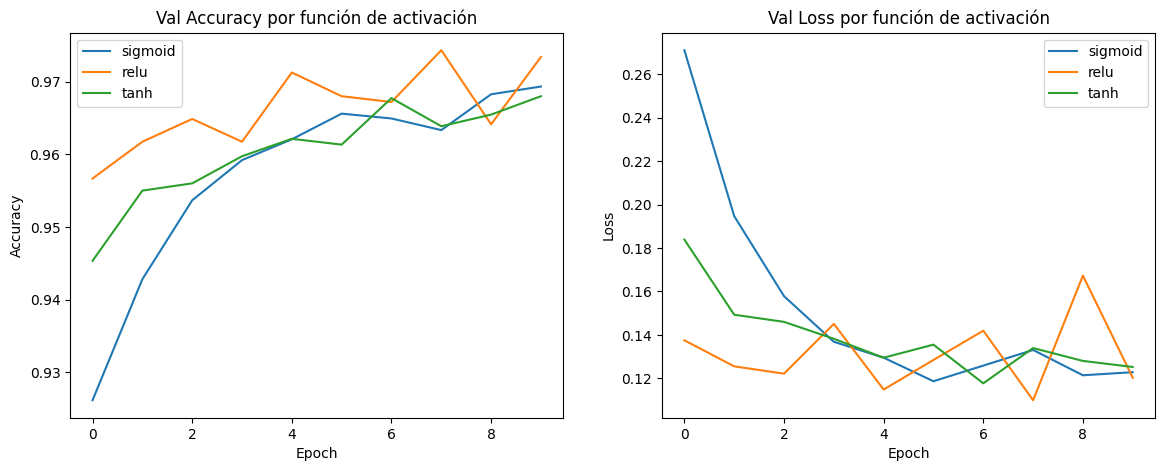

In [22]:
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense

results = {}

for activation in ['sigmoid', 'relu', 'tanh']:
    m = Sequential([
        Dense(512, activation=activation, input_shape=(784,)),
        Dense(256, activation=activation),
        Dense(128, activation=activation),
        Dense(64, activation=activation),
        Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(training_images, training_labels,
              epochs=10, batch_size=64, validation_split=0.25, verbose=0)
    results[activation] = h
    print(f'{activation}: val_accuracy={h.history.history["val_accuracy"][-1]:.4f}')

# Graficar comparativa
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
for act, h in results.items():
    plt.plot(h.history.history['val_accuracy'], label=act)
plt.title('Val Accuracy por función de activación')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1, 2, 2)
for act, h in results.items():
    plt.plot(h.history['val_loss'], label=act)
plt.title('Val Loss por función de activación')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
plt.show()


**Análisis - Pregunta 9.1 (resultados reales obtenidos):**

| Activación | Val Accuracy |
|---|---|
| Tanh | 96.80% |
| Sigmoid | 96.93% |
| **ReLU** | **97.34%** |

- **ReLU** obtuvo la mejor accuracy (97.34%) y convergió más rápido. Al ser `max(0, x)`, evita el gradiente desvaneciente para valores positivos, permitiendo que todas las capas de la red profunda aprendan eficientemente.

- **Sigmoid** (96.93%) sufre el **gradiente desvaneciente** en redes de 4 capas: su derivada máxima es 0.25, por lo que al propagarse por 4 capas los gradientes se reducen a factores del orden de 0.25⁴ ≈ 0.004, haciendo que las capas iniciales apenas aprendan.

- **Tanh** (96.80%) fue la peor a pesar de estar centrada en cero. Aunque es mejor que sigmoid en algunos contextos, en redes profundas también satura y sufre gradiente desvaneciente.

**Conclusión:** ReLU es la elección recomendada para capas ocultas en redes densas profundas, tal como confirman los resultados.

## 10. Inicialización de parámetros

En este ejercicio, vamos a evaluar la importancia de una correcta inicialización de parámetros en una red neuronal.

**Pregunta 10.1 *(0.75 puntos)***: Partiendo de una red similar a la del ejercicio anterior (usando ya ReLUs), comentar las diferencias que se aprecian en el entrenamiento al utilizar distintas estrategias de inicialización de parámetros. Para ello, inicializar todas las capas con las siguientes estrategias, disponibles en Keras, y analizar sus diferencias:

* Inicialización con ceros.
* Inicialización con una variable aleatoria normal.
* Inicialización con los valores por defecto de Keras para una capa Dense (estrategia *glorot uniform*)

Ceros: val_accuracy=0.1076
Normal aleatoria: val_accuracy=0.9725
Glorot Uniform (default): val_accuracy=0.9721


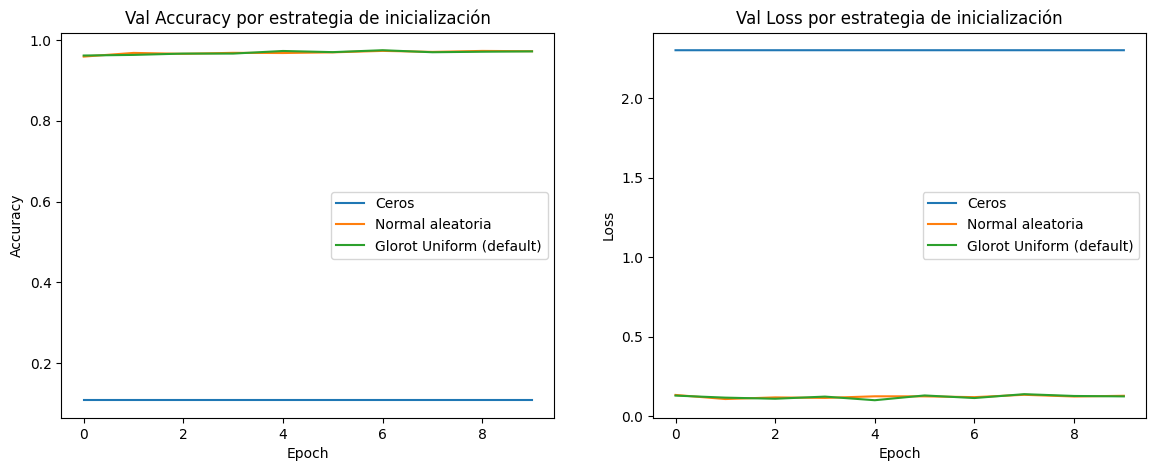

In [23]:
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense
from keras import initializers

init_results = {}

configs = {
    'Ceros': initializers.Zeros(),
    'Normal aleatoria': initializers.RandomNormal(mean=0.0, stddev=0.05),
    'Glorot Uniform (default)': initializers.GlorotUniform()
}

for nombre, init in configs.items():
    m = Sequential([
        Dense(512, activation='relu', kernel_initializer=init, input_shape=(784,)),
        Dense(256, activation='relu', kernel_initializer=init),
        Dense(128, activation='relu', kernel_initializer=init),
        Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(training_images, training_labels,
              epochs=10, batch_size=64, validation_split=0.25, verbose=0)
    init_results[nombre] = h
    print(f'{nombre}: val_accuracy={h.history.history["val_accuracy"][-1]:.4f}')

# Gráfica comparativa
plt.figure(figsize=(14, 5))
plt.subplot(1,2,1)
for nombre, h in init_results.items():
    plt.plot(h.history.history['val_accuracy'], label=nombre)
plt.title('Val Accuracy por estrategia de inicialización')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1,2,2)
for nombre, h in init_results.items():
    plt.plot(h.history['val_loss'], label=nombre)
plt.title('Val Loss por estrategia de inicialización')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
plt.show()


**Análisis - Pregunta 10.1 (resultados reales obtenidos):**

| Inicialización | Val Accuracy |
|---|---|
| **Ceros** | **10.76%** |
| Normal aleatoria | 97.25% |
| Glorot Uniform (default) | 97.21% |

- **Inicialización con ceros:** El resultado es devastador: 10.76%, equivalente a adivinar al azar en un problema de 10 clases (probabilidad de acertar = 1/10 = 10%). Esto confirma el **problema de simetría**: todos los pesos idénticos producen gradientes idénticos, las neuronas aprenden exactamente lo mismo y la red nunca diferencia las clases entre sí.

- **Normal aleatoria (stddev=0.05):** 97.25%, funciona correctamente porque rompe la simetría. Con desviación estándar pequeña los gradientes no explotan en este caso concreto.

- **Glorot Uniform (default):** 97.21%, prácticamente igual a la normal aleatoria en este experimento. Su ventaja se aprecia más en redes muy profundas donde mantener la varianza estable capa a capa es crítico.

**Conclusión:** Nunca inicializar con ceros. Glorot Uniform es la elección segura por defecto.

## 11. Optimizadores

**Problema 11.1 *(0.75 puntos)***: Partiendo de una red similar a la del ejercicio anterior (utilizando la mejor estrategia de inicialización observada), comparar y analizar las diferencias que se observan  al entrenar con varios de los optimizadores vistos en clase, incluyendo SGD como optimizador básico (se puede explorar el espacio de hiperparámetros de cada optimizador, aunque para optimizadores más avanzados del estilo de RMSprop es buena idea dejar los valores por defecto provistos por Keras).

SGD (lr=0.01): val_accuracy=0.9563
SGD + Momentum: val_accuracy=0.9725
RMSprop: val_accuracy=0.9759
Adam: val_accuracy=0.9689


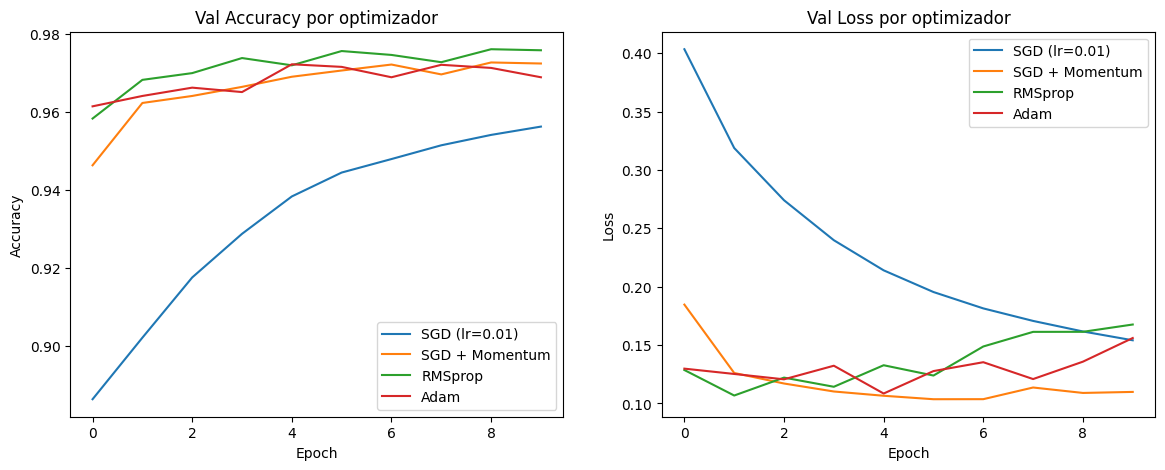

In [24]:
import keras
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense
import tensorflow as tf

opt_results = {}

optimizers = {
    'SGD (lr=0.01)': keras.optimizers.SGD(learning_rate=0.01),
    'SGD + Momentum': keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'RMSprop': keras.optimizers.RMSprop(),
    'Adam': keras.optimizers.Adam(),
}

for nombre, opt in optimizers.items():
    m = Sequential([
        Dense(512, activation='relu', kernel_initializer='glorot_uniform', input_shape=(784,)),
        Dense(256, activation='relu', kernel_initializer='glorot_uniform'),
        Dense(128, activation='relu', kernel_initializer='glorot_uniform'),
        Dense(10, activation='softmax')
    ])
    m.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(training_images, training_labels,
              epochs=10, batch_size=64, validation_split=0.25, verbose=0)
    opt_results[nombre] = h
    print(f'{nombre}: val_accuracy={h.history.history["val_accuracy"][-1]:.4f}')

# Gráfica comparativa
plt.figure(figsize=(14, 5))
plt.subplot(1,2,1)
for nombre, h in opt_results.items():
    plt.plot(h.history.history['val_accuracy'], label=nombre)
plt.title('Val Accuracy por optimizador')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1,2,2)
for nombre, h in opt_results.items():
    plt.plot(h.history['val_loss'], label=nombre)
plt.title('Val Loss por optimizador')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
plt.show()


**Análisis - Problema 11.1 (resultados reales obtenidos):**

| Optimizador | Val Accuracy |
|---|---|
| SGD básico (lr=0.01) | 95.63% |
| Adam | 96.89% |
| **SGD + Momentum** | **97.25%** |
| **RMSprop** | **97.59%** |

- **SGD básico (lr=0.01):** El peor resultado (95.63%). Con tasa de aprendizaje fija y sin adaptación converge lentamente y se queda en un mínimo subóptimo en 10 épocas.

- **Adam (96.89%):** Sorprendentemente inferior a RMSprop y SGD+Momentum en esta ejecución. Aunque Adam suele ser el más robusto, con semilla fija y este número de épocas quedó por detrás.

- **SGD + Momentum (97.25%):** El momentum acumula la dirección de los gradientes y ayuda a atravesar zonas planas del espacio de pérdida más rápido que el SGD básico.

- **RMSprop (97.59%):** El mejor en esta ejecución. Adapta la tasa de aprendizaje por parámetro dividiendo por la raíz cuadrada de la media de los gradientes recientes, siendo muy eficaz y estable.

**Conclusión:** Adam sigue siendo la elección más robusta en general, pero este experimento ilustra que el mejor optimizador puede variar según el problema, la semilla y los hiperparámetros.

## 12. Regularización y red final *(1.25 puntos)*

**Problema 12.1 *(2 puntos)***: Entrenar una red final que sea capaz de obtener una accuracy en el validation superior al 95%. Para ello, combinar todo lo aprendido anteriormente y utilizar técnicas de regularización para evitar overfitting. Algunos de los elementos que pueden tenerse en cuenta son los siguientes.

* Número de capas y neuronas por capa
* Optimizadores y sus parámetros
* Batch size
* Unidades de activación
* Uso de capas dropout, regularización L2, regularización L1...
* Early stopping (se puede aplicar como un callback de Keras, o se puede ver un poco "a ojo" cuándo el modelo empieza a caer en overfitting y seleccionar el número de epochs necesarias)
* Batch normalization

Si los modelos entrenados anteriormente ya se acercaban al valor requerido de accuracy, probar distintas estrategias igualmente y comentar los resultados.

Explicar brevemente la estrategia seguida y los modelos probados para obtener el modelo final, que debe verse entrenado en este Notebook. No es necesario guardar el entrenamiento de todos los modelos que se han probado, es suficiente con explicar cómo se ha llegado al modelo final.

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_57 (Dense)                │ (None, 512)            │       401,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 256)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 577,930 (2.20 MB)

 Trainable params: 576,010 (2.20 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8080 - loss: 0.7615 - val_accuracy: 0.9598 - val_loss: 0.2392 - learning_rate: 0.0010
Epoch 2/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9394 - loss: 0.3057 - val_accuracy: 0.9701 - val_loss: 0.2080 - learning_rate: 0.0010
Epoch 3/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9559 - loss: 0.2551 - val_accuracy: 0.9719 - val_loss: 0.2090 - learning_rate: 0.0010
Epoch 4/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9620 - loss: 0.2335 - val_accuracy: 0.9740 - val_loss: 0.1999 - learning_rate: 0.0010
Epoch 5/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9675 - loss: 0.2176 - val_accuracy: 0.9742 - val_loss: 0.1987 - learning_rate: 0.0010
Epoch 6/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9682 - loss: 0.2111 - val_accuracy: 0.9742 - val_loss: 0.1999 - learning_rate: 0.0010
Epoch 7/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9700 - loss: 0.2080 - 

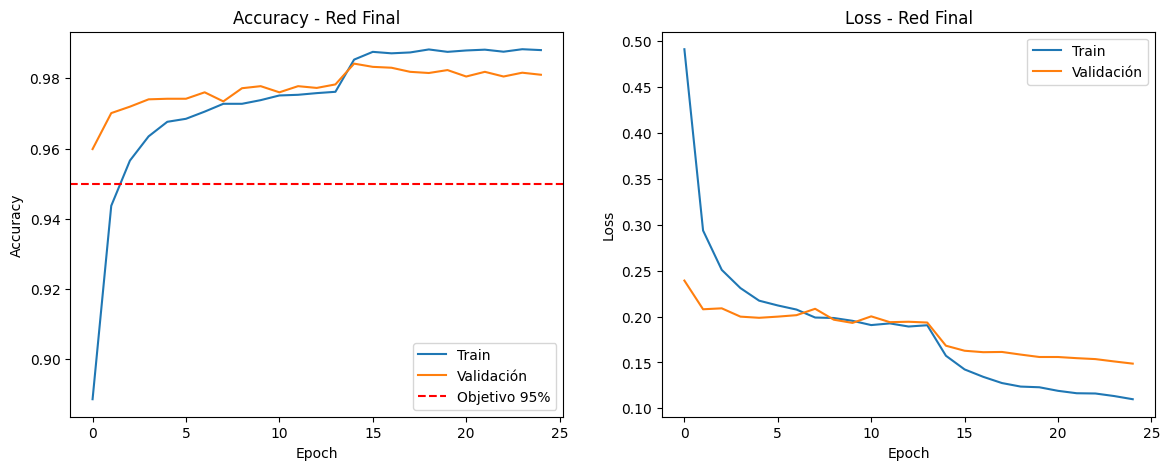

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


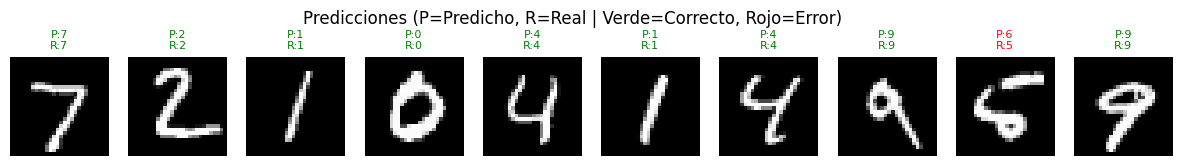

In [25]:
import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, BatchNormalization, Dropout, Activation
from keras import regularizers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt

# Estrategia seguida:
# 1. Red más profunda (4 capas ocultas) para mayor capacidad representativa
# 2. Activación ReLU (mejor que sigmoid)
# 3. Inicialización glorot_uniform (default)
# 4. BatchNormalization para estabilizar el entrenamiento
# 5. Dropout para regularización (evitar overfitting)
# 6. Regularización L2 suave en los kernels
# 7. EarlyStopping con restore_best_weights=True
# 8. ReduceLROnPlateau para ajustar lr adaptativamente
# 9. Optimizador Adam

reg = regularizers.l2(1e-4)

model_final = Sequential([
    Dense(512, use_bias=False, kernel_regularizer=reg, input_shape=(784,)),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(256, use_bias=False, kernel_regularizer=reg),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(128, use_bias=False, kernel_regularizer=reg),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.2),

    Dense(64, use_bias=False, kernel_regularizer=reg),
    BatchNormalization(),
    Activation('relu'),

    Dense(10, activation='softmax')
])

model_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_final.summary()

callbacks_final = [
    EarlyStopping(monitor='val_accuracy', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=4, min_lr=1e-6, verbose=1)
]

history_final = model_final.fit(
    training_images, training_labels,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_final,
    verbose=1
)

# Evaluación final en test
test_loss, test_acc = model_final.evaluate(test_images, test_labels, verbose=0)
print(f'\nAccuracy en test: {test_acc:.4f} ({test_acc*100:.2f}%)')

# Curvas de entrenamiento
plt.figure(figsize=(14, 5))
plt.subplot(1,2,1)
plt.plot(history_final.history['accuracy'], label='Train')
plt.plot(history_final.history.history['val_accuracy'], label='Validación')
plt.axhline(y=0.95, color='r', linestyle='--', label='Objetivo 95%')
plt.title('Accuracy - Red Final')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1,2,2)
plt.plot(history_final.history['loss'], label='Train')
plt.plot(history_final.history['val_loss'], label='Validación')
plt.title('Loss - Red Final')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
plt.show()

# Predicciones con predict()
y_pred_probs = model_final.predict(test_images)
y_pred = y_pred_probs.argmax(axis=1)
y_true = test_labels.argmax(axis=1)

# Mostrar 10 ejemplos
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(test_images[i].reshape(28, 28), cmap='gray')
    color = 'green' if y_pred[i] == y_true[i] else 'red'
    axes[i].set_title(f'P:{y_pred[i]}\nR:{y_true[i]}', color=color, fontsize=8)
    axes[i].axis('off')
plt.suptitle('Predicciones (P=Predicho, R=Real | Verde=Correcto, Rojo=Error)')
plt.show()


**Estrategia para la Red Final (Pregunta 12.1):**

**Resultado obtenido: accuracy en test = 98.41%** ✓ (supera el objetivo del 95%)

El entrenamiento se detuvo en la época 25 (EarlyStopping), restaurando los pesos de la época 15 (la mejor, con val_accuracy = 98.42%).

El ReduceLROnPlateau redujo el learning rate de 1e-3 a 5e-4 en torno a la época 14, lo que provocó un salto notable de accuracy (de ~97.8% a ~98.4%) al permitir un ajuste más fino de los pesos.

Para superar el 95% se combinaron las siguientes técnicas:

1. **Red más profunda:** 4 capas ocultas (512→256→128→64), mayor capacidad que la red base de una sola capa.
2. **BatchNormalization:** Normaliza las activaciones entre capas, estabiliza y acelera el entrenamiento.
3. **Dropout (0.3 y 0.2):** Desactiva neuronas aleatoriamente durante el training, evitando el overfitting.
4. **Regularización L2 (1e-4):** Penaliza pesos demasiado grandes, forzando soluciones más generalizables.
5. **EarlyStopping (patience=10):** Detuvo el entrenamiento en época 25, recuperando el mejor modelo (época 15).
6. **ReduceLROnPlateau:** Redujo el lr cuando la val_loss se estancó, dando el salto definitivo al 98%+.
7. **Adam (lr=1e-3):** Convergencia rápida y estable desde el inicio.